In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2023-11-13 11:38:10.401127: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2023-11-13 11:38:10.473544: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2023-11-13 11:38:10.473595: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2023-11-13 11:38:10.473657: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2023-11-13 11:38:10.486192: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2023-11-13 11:38:10.486660: I tensorflow/core/platform/cpu_feature_guard.cc:182] This Tens

## Params

In [14]:
V_width_array = np.arange(20).astype(int) + 1
V_E_buffer = 0
E_width = 1

N_training_repeats = 5  # a different group of neurons will be selected for each
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 8,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

# Put variable names here for parameters we want saved.
save_vars = {
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "opt_params",
    "V_width_array",
    "V_E_buffer",
    "E_width",
    "train_fraction",
    "samp_keep",
}

## Prepare data

In [15]:
data_path = os.path.join(project_folder, 'data', 'bar_stim_data')
D = ds.DataBar(data_path)

## Run analysis

In [16]:
experiment_dims = (len(V_width_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)
save_vars.update(
    {
        "mi_averages_train",
        "mi_averages_test",
        "mi_stdevs_train",
        "mi_stdevs_test",
        "train_points",
        "test_points",
    }
)

for i, V_width in tqdm(enumerate(V_width_array)):
    for training_repeat in range(N_training_repeats):
        critic_function = mds.SeparableCritic(**critic_params)

        # Domains, training and test subsets
        D.reset()
        D.trim(20)
        V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[i, training_repeat] = current_train_points
        test_points[i, training_repeat] = current_test_points

        # Train current
        als.train_NCE(X=V.X, Y=E.X, critic_function=critic_function, **opt_params)

        # Measure InfoNCE for train
        mi_train = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[i, training_repeat] = mi_train["mi"]
        mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        mi_test = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[i, training_repeat] = mi_test["mi"]
        mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        critic_function_array[i, training_repeat] = critic_function

0it [00:00, ?it/s]

0it [00:16, ?it/s]


KeyboardInterrupt: 

## Save

In [ ]:
# select variables
critic_type = type(critic_function_array[0, 0])
save_vars.update({"critic_type"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [ ]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
full_file_path = os.path.join(save_directory, 'all neurons bar.dat')
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)
tools.record_parameters(full_file_path, output_data)

## Reload and plot

In [3]:
load_path = project_folder + '/analyses/Markovianity/saved/all neurons bar.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

In [4]:
data_dict.keys()

dict_keys(['mi_averages_train', 'V_width_array', 'train_points', 'E_width', 'critic_params', 'samp_keep', 'mi_stdevs_test', 'test_points', 'N_training_repeats', 'critic_type', 'mi_stdevs_train', 'opt_params', 'train_fraction', 'mi_averages_test', 'mi_measurement_params', 'V_E_buffer'])

In [5]:
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)

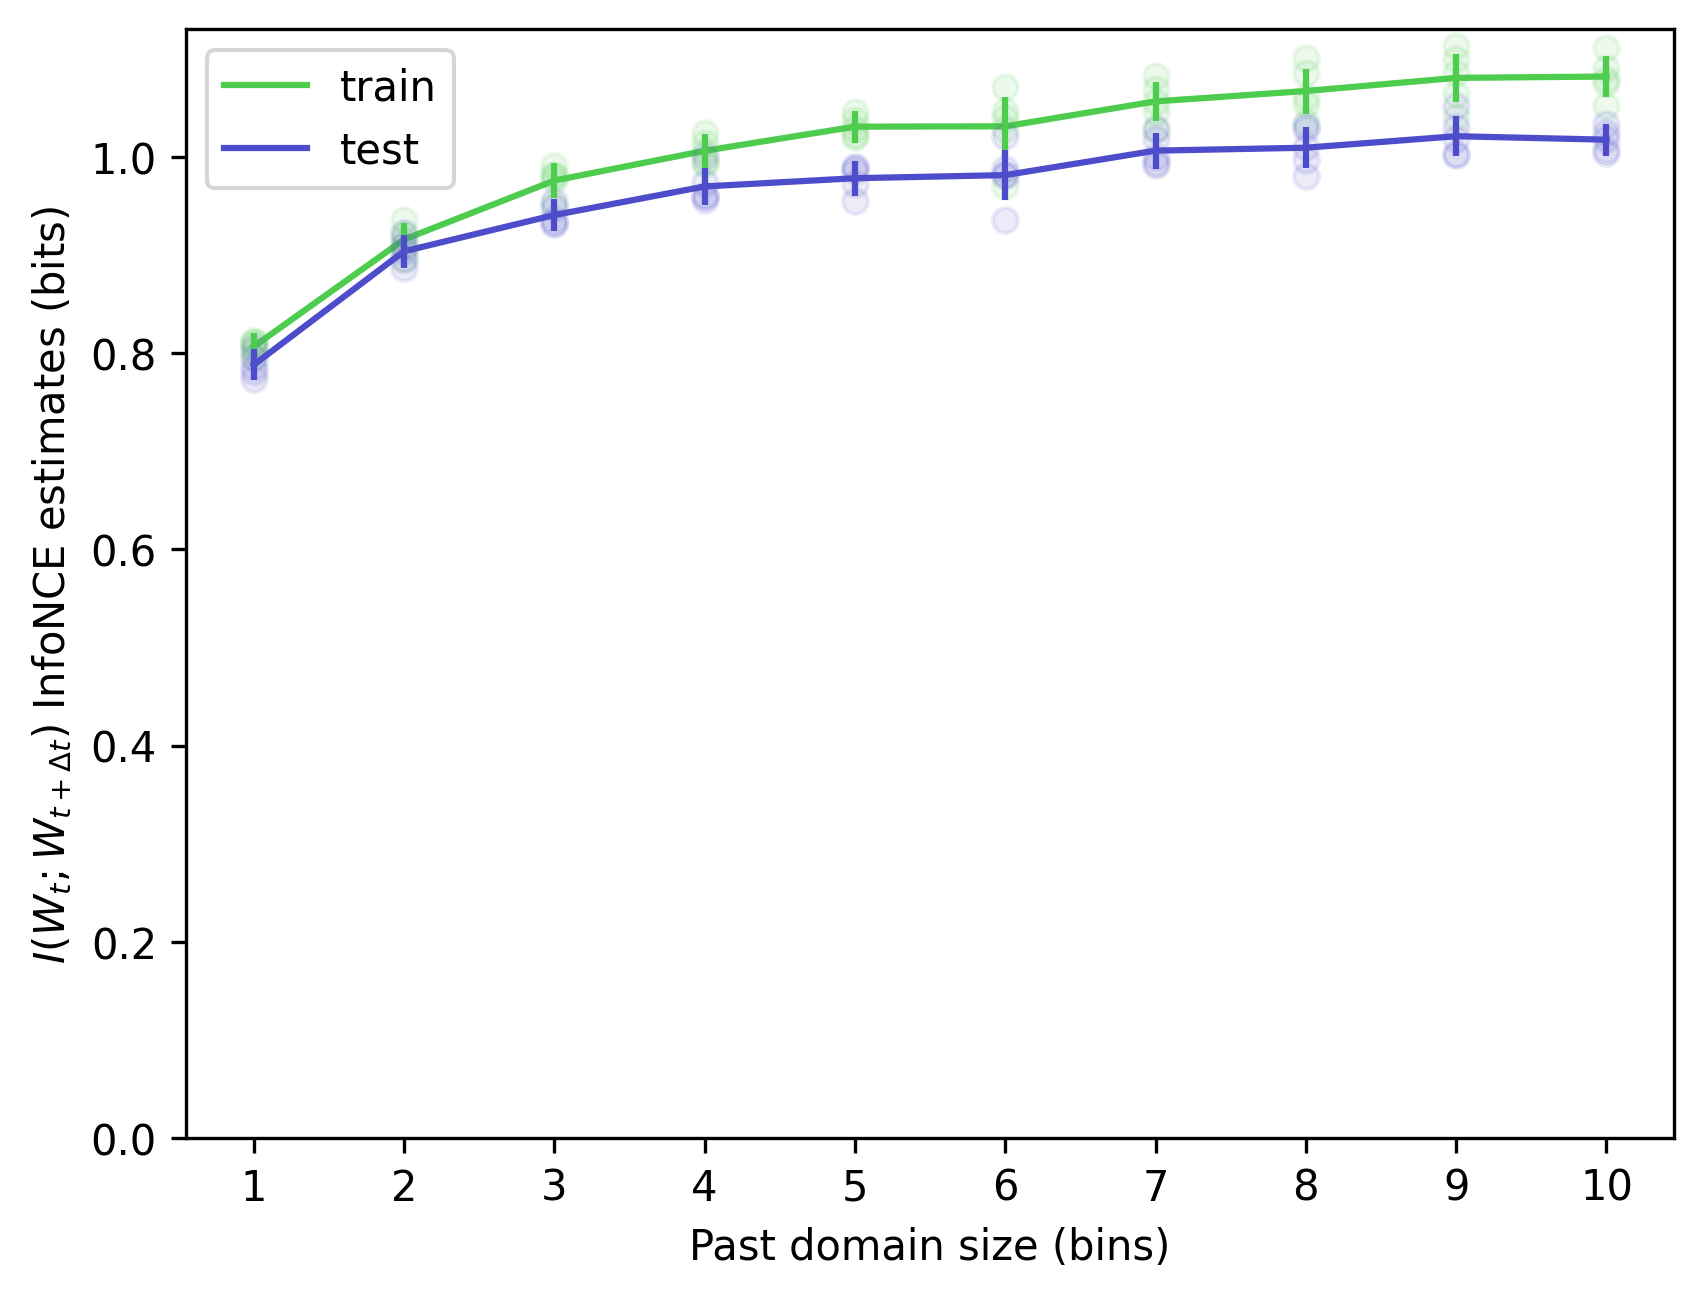

In [6]:
x = data.V_width_array

c1 = 0.3
c2 = 0.8
alp = 0.1
plt.figure(dpi=300)
plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='train')
plt.plot(x, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='test');
plt.plot(x, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))
plt.ylim(ymin=0)
ax = plt.gca()
ax.set_xticks(x)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('Past domain size (bins)')
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();

In [7]:
x = data.V_width_array
y_train = (average_train[-1] - average_train)/np.log(2)
t_halfmax_train = tools.arg_half_max(y_train)
y_test = (average_test[-1] - average_test)/np.log(2)
t_halfmax_test = tools.arg_half_max(y_test)
tau_train = t_halfmax_train / np.log(2)
tau_test = t_halfmax_test / np.log(2)
y_train_theory = np.exp( - (x - 1) / tau_train) * y_train[0]
y_test_theory = np.exp(- (x - 1) / tau_test) * y_test[0]

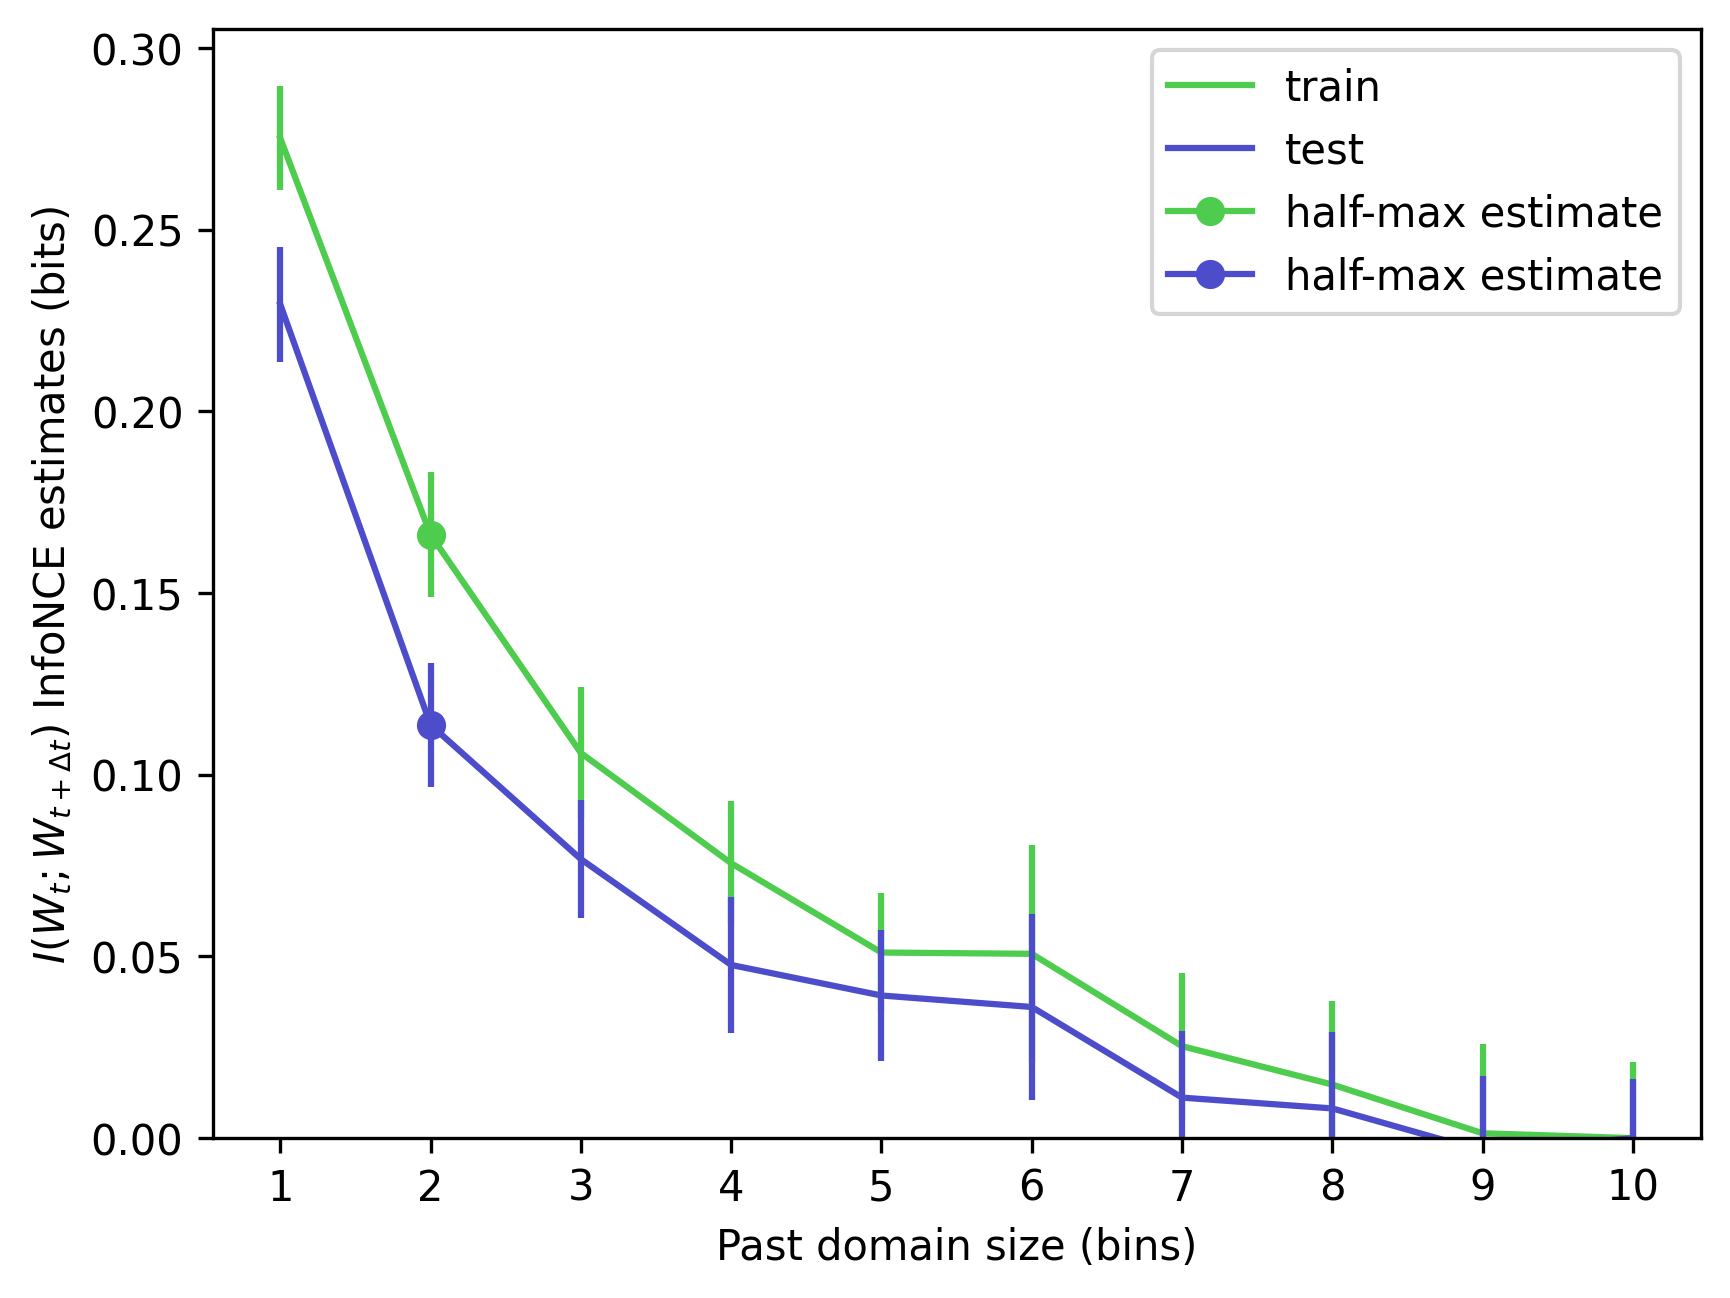

In [10]:
c1 = 0.3
c2 = 0.8
alp = 0.1
plt.figure(dpi=300)
plt.plot(x, y_train, color=(c1,c2,c1), label='train')
plt.plot(x, y_test, color=(c1,c1,c2), label='test');

# plt.plot(x, y_train_theory, 'k')
# plt.plot(x, y_test_theory, 'k')

plt.plot(x[t_halfmax_train], y_train[t_halfmax_train], color=(c1,c2,c1), marker='o', label='half-max estimate')
plt.plot(x[t_halfmax_test], y_test[t_halfmax_test], color=(c1,c1,c2), marker='o', label='half-max estimate');

plt.errorbar(x, y_train, yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, y_test, yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))

plt.ylim(ymin=0)
ax = plt.gca()
ax.set_xticks(x)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('Past domain size (bins)')
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();